# **Fine tuning a pre-trained model**

In [144]:
import os
import re
import torch
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [145]:
img_folder = "/content/training"
img_height, img_width = 480, 640
batch_size = 16
learning_rate = 1e-4
num_epochs = 100
model_save_path = "model_final_aug.pt"

In [146]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [147]:
class ImageNameDataset(Dataset):
    def __init__(self, folder, transform=None):
        self.folder = folder
        self.transform = transform
        self.files = [f for f in os.listdir(folder) if f.endswith('.png')]
        self.classes = sorted(list({re.match(r'([a-zA-Z]+)', f).group(1) for f in self.files}))
        self.class_to_idx = {c:i for i,c in enumerate(self.classes)}

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        file_name = self.files[idx]
        path = os.path.join(self.folder, file_name)
        img = Image.open(path).convert("RGB")
        label_str = re.match(r'([a-zA-Z]+)', file_name).group(1)
        label = self.class_to_idx[label_str]
        if self.transform:
            img = self.transform(img)
        return img, label

In [148]:
dataset = ImageNameDataset(img_folder)
print("found classes:", dataset.classes)
print("Total classes:", len(dataset))

found classes: ['book', 'cookiebox', 'cup', 'ketchup', 'sugar', 'sweets', 'tea']
Total classes: 144


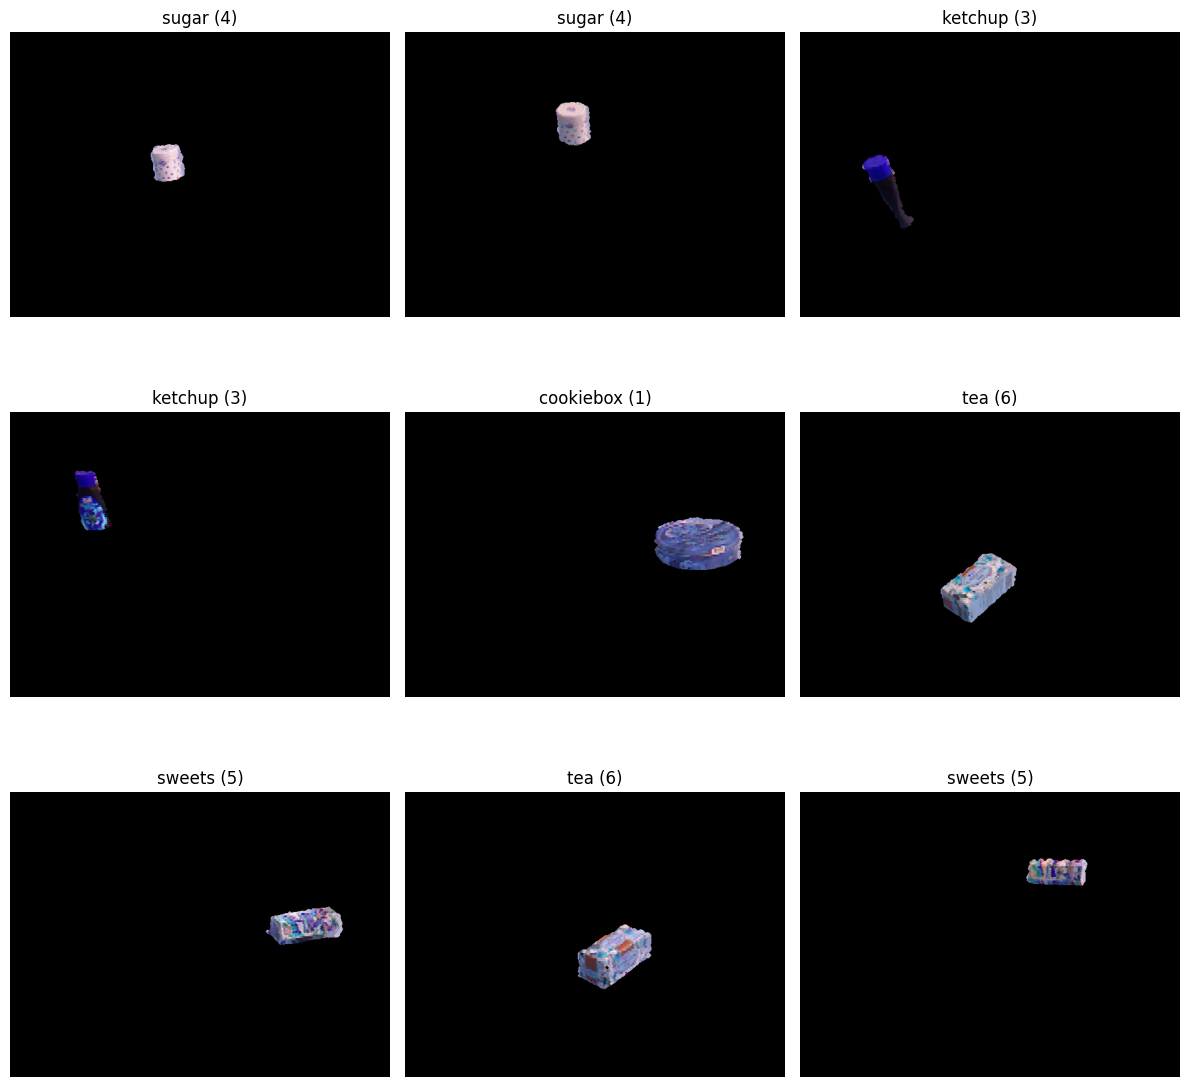

In [149]:
dataset = ImageNameDataset(img_folder, transform=transforms.ToTensor())
class_names = dataset.classes

def show_images_grid(dataset, n=9):
    class_names = dataset.classes
    n = min(n, len(dataset))
    cols = 3
    rows = (n + cols - 1) // cols

    plt.figure(figsize=(cols*4, rows*4))

    for i in range(n):
        img, label = dataset[i]
        img = img.permute(1, 2, 0).numpy()
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(img)
        ax.set_title(f"{class_names[label]} ({label})")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

show_images_grid(dataset, n=9)

In [150]:
img_height, img_width = 224, 224

train_transform = transforms.Compose([
    transforms.Resize((img_height,img_width)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1,0.1),
        scale=(0.9,1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

In [151]:
num_classes = len(dataset.classes)

In [152]:
model = models.resnet18(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

'''
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True
'''

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.BatchNorm1d(num_ftrs),
    nn.Dropout(0.5),
    nn.Linear(num_ftrs, num_classes)
)

for param in model.fc.parameters():
    param.requires_grad = True

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [153]:
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

In [154]:
num_epochs = 5
batch_size = 8
model_save_path = "tuned_model.pt"

In [155]:
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

In [156]:
for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in tqdm(train_loader):
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = running_corrects.double() / len(train_loader.dataset)
    print(f"Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")


Epoch 1/5


100%|██████████| 18/18 [00:01<00:00,  9.86it/s]


Loss: 1.9034 | Acc: 0.2847

Epoch 2/5


100%|██████████| 18/18 [00:02<00:00,  8.94it/s]


Loss: 0.8943 | Acc: 0.7569

Epoch 3/5


...

Loss: 0.5513 | Acc: 0.8819

Epoch 4/5


100%|██████████| 18/18 [00:01<00:00, 10.91it/s]


Loss: 0.3983 | Acc: 0.8889

Epoch 5/5


100%|██████████| 18/18 [00:01<00:00, 10.79it/s]

Loss: 0.3796 | Acc: 0.8889


In [157]:
torch.save(model.state_dict(), model_save_path)
print(f"\nSaving model as: {model_save_path}")


Saving model as: tuned_model.pt


In [158]:
test_folder = "test/"
img_height, img_width = 224, 224
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_names = dataset.classes

In [159]:
test_transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

In [160]:
def show_image_pred(img_path):
    img = Image.open(img_path).convert("RGB")
    img_tensor = test_transform(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        outputs = model(img_tensor)
        _, pred = torch.max(outputs, 1)
        pred_class = class_names[pred.item()]

    plt.imshow(img)
    plt.title(f"Predicted: {pred_class}")
    plt.axis('off')
    plt.show()


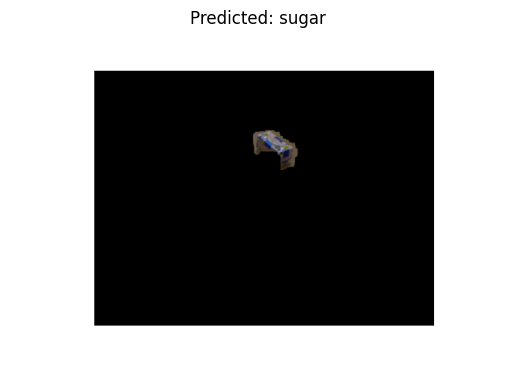

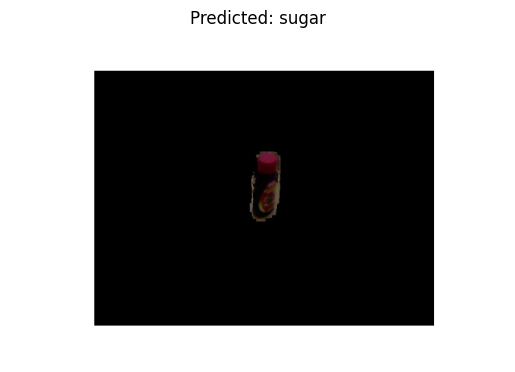

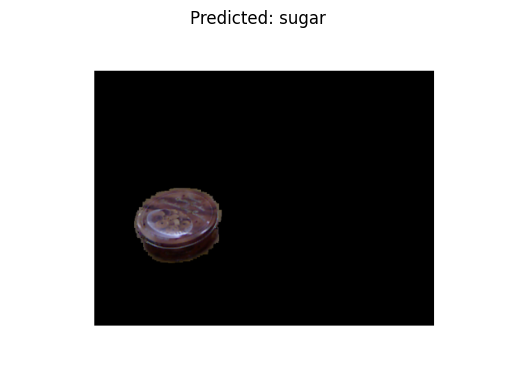

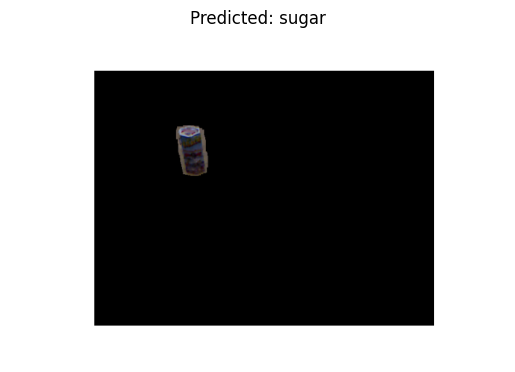

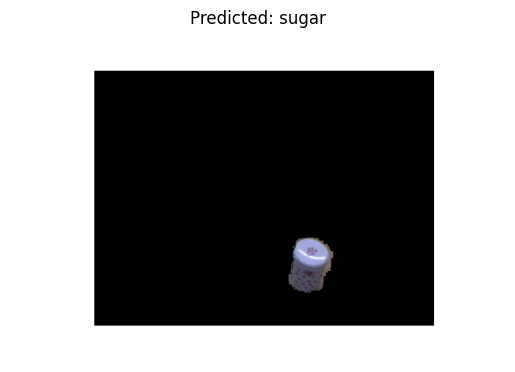

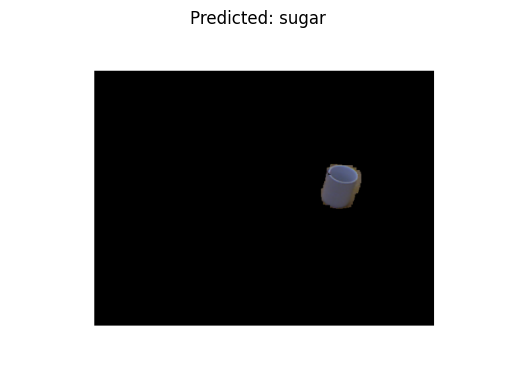

In [161]:
for f in os.listdir(test_folder):
    if f.endswith('.png'):
        show_image_pred(os.path.join(test_folder, f))

# **Scratch model CNN**

In [162]:
import torch.nn.functional as F

class TinyCNN(nn.Module):
    def __init__(self, num_classes, img_height=480, img_width=640):
        super(TinyCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2,2)
        self.dropout = nn.Dropout(0.3)

        self.flatten_size = 32 * (img_height // 2) * (img_width // 2)

        self.fc1 = nn.Linear(self.flatten_size, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [163]:
model = TinyCNN(num_classes, img_height=480, img_width=640).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [164]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(0.9,1.1)),
    transforms.ToTensor(),
])

In [165]:
dataset.transform = train_transform

train_loader = DataLoader(dataset, batch_size=4, shuffle=True)

In [166]:
num_epochs = 5

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    model.train()

    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = running_corrects.double() / len(train_loader.dataset)

    print(f"Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")

torch.save(model.state_dict(), "tinycnn.pt")
print("\nSaved model tinycnn")


Epoch 1/5
Loss: 8.8968 | Acc: 0.1736

Epoch 2/5
Loss: 1.7991 | Acc: 0.3403

Epoch 3/5
Loss: 1.4323 | Acc: 0.4236

Epoch 4/5
Loss: 1.1826 | Acc: 0.5069

Epoch 5/5
Loss: 0.9744 | Acc: 0.6111

Saved model tinycnn


In [167]:
def test_model_print(model, test_folder, class_names, device):
    model.eval()
    transform = transforms.Compose([
        transforms.Resize((480,640)),
        transforms.ToTensor(),
    ])

    for f in os.listdir(test_folder):
        if f.endswith(".png"):
            path = os.path.join(test_folder, f)
            img = Image.open(path).convert("RGB")
            img_tensor = transform(img).unsqueeze(0).to(device)

            with torch.no_grad():
                output = model(img_tensor)
                pred_idx = torch.argmax(output, dim=1).item()
                pred_class = class_names[pred_idx]

            print(f"{f} -> Prediction: {pred_class}")

test_folder = "test/"
class_names = dataset.classes

test_model_print(model, test_folder, class_names, device)

obj6.png -> Prediction: book
obj3.png -> Prediction: book
obj2.png -> Prediction: book
obj5.png -> Prediction: book
obj1.png -> Prediction: book
obj4.png -> Prediction: book
